# Plan constraint assessment

**Recipe 44** · Level 4 (Advanced) · Decision type: `Noul`

Evaluate each candidate plan against individual user constraints so deterministic policy can reject ineligible plans and route unresolved judgments to review.

Sources:

- S02: [TypeSafe AI: Primitives (Questions)](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe AI: Confidence](https://docs.typesafe.ai/confidence)
- S04: [TypeSafe AI: How to build with TypeSafe](https://docs.typesafe.ai/concepts/how-to-build-with-system-one)
- S06: [TypeSafe AI: Cookbooks](https://docs.typesafe.ai/cookbooks)

## What you will build

An agent proposes a candidate plan to carry out a user's request, and the user has stated four constraints the plan must respect: budget, timeline, vendor and data handling. For each (plan, constraint) pair you ask Jev one independent `Noul`: does the plan violate this one constraint? All four propositions about one plan are asked together, in one request. Python never asks the model to weigh the four against each other: a deterministic rule in `helpers.py` composes the four answers into exactly one of three outcomes -- `ineligible` (reject the plan outright), `review` (send it to a person because at least one judgment is not confident enough to trust), or `eligible` (let it proceed automatically) -- and a single confident violation is enough to make a plan ineligible even when every other constraint reads perfectly clean. By the end you will have seen one plan's four typed answers, the rule that composes them, a plan that satisfies every constraint but one, and an evaluation that measures what a confidence gate actually changes rather than assuming it.

## Setup and run mode

The notebook runs from its own folder with the standard library and `jev_cookbook` only. `get_backend(fixtures=...)` is called exactly once, below, and replays the 35 stored answers in `fixtures/responses.json` offline; setting `JEV_COOKBOOK_LIVE=1` (see the README) swaps in live calls to the same four question definitions and changes nothing else. `run_header` states which mode ran. Every request this notebook makes goes through `ask`, defined below, which counts every attempt (never deduplicated by id) rather than trusting a count computed some other way -- "What was and was not measured" checks that count against the fixture file directly. Each of the 35 candidate plans (15 `validation`, 15 `test`, 5 `demo`) needs exactly one request (all four constraint propositions are independent questions about the same plan, so they are asked together), so this notebook's **request** count and its **question** count are not the same thing: 35 requests produce 140 (plan, constraint) decisions, four per plan.

In [1]:
from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    evaluate_outcomes,
    evaluate_threshold,
    multilabel_from_noul,
    multilabel_metrics,
    pool_label_decisions,
    select_confidence_threshold,
    select_threshold,
)
from jev_cookbook.fixtures import load_inputs, load_labels, load_responses, responses_path
from jev_cookbook.simulation import ReviewQueue
from jev_cookbook.style import apply_style, plot_risk_coverage, run_header, show_answer

apply_style()
helpers = load_helpers()  # this recipe's helpers.py, loaded by path
examples = load_inputs()
labels = load_labels()
backend = get_backend(fixtures=responses_path())  # the one and only call in this notebook
questions = helpers.build_questions()

# N for the header is the number of plans the metrics are about: validation and test. The
# five demo plans are shown below but never scored.
scored = [e for e in examples if e.split not in ("train", "demo")]

offline = backend.mode in ("synthetic", "scripted")
check = " (a pipeline check, not a Jev result)" if offline else ""
selection = " (selection: chosen on validation)"

request_log = []


def ask(example):
    # Counts every attempt, never deduplicated by id: a double-decide on the same id shows up
    # here as a longer request_log, not hidden inside a dict keyed by id.
    request_log.append(example.id)
    return backend.decide(helpers.build_state(example.fields), questions)


run_header(
    44,
    "Plan constraint assessment",
    backend=backend,
    n_examples=len(scored),
)

Recipe 44: Plan constraint assessment
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 30 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The state is everything Jev sees, and Python builds it: the user's own four constraint statements, and the plan's own description, nothing else. Each example in `fixtures/inputs.jsonl` carries `fields`: `user_constraints` (the budget limit, deadline, approved vendor list and data scope, each baked into one fixed-wording sentence per constraint) and `plan` (the candidate plan's own text: what it does, its estimated cost, target completion, vendor and what happens to the user's data), plus `cost`, the plan's own numeric estimate Python reads back out for the stateful walkthrough's bookkeeping below. `build_state` passes on only `user_constraints` and `plan` -- `cost` never reaches the model a second time, separately from however the plan's own prose already states it.

In [2]:
import json

demo = {e.id: e for e in examples if e.split == "demo"}
flag_demo = demo["d01-flag"]
print("Python has:")
print(json.dumps(flag_demo.fields, indent=2))
state = helpers.build_state(flag_demo.fields)
print("Jev sees:")
print(json.dumps(state, indent=2))

Python has:
{
  "user_constraints": {
    "budget": "Budget constraint: total plan cost must not exceed $3000.",
    "timeline": "Timeline constraint: every step must be completed by April 1.",
    "vendor": "Vendor constraint: only these vendors are pre-approved for this task: Crestline Logistics.",
    "data_handling": "Data handling constraint: the user's personal data may be shared only with Crestline Logistics."
  },
  "plan": "Ship replacement workstations to the satellite office through Crestline Logistics. Estimated total cost: $5200. Target completion: March 25. Vendor used: Crestline Logistics. The plan shares only the delivery schedule with Crestline Logistics.",
  "cost": 5200
}
Jev sees:
{
  "user_constraints": {
    "budget": "Budget constraint: total plan cost must not exceed $3000.",
    "timeline": "Timeline constraint: every step must be completed by April 1.",
    "vendor": "Vendor constraint: only these vendors are pre-approved for this task: Crestline Logistics.",


## The questions

Four independent propositions describe the same plan, so `backend.decide` sends them together in one request: TypeSafe's primitives page ([S02](https://docs.typesafe.ai/primitives)) says independent questions over the same state belong in one request. Each is written as a statement that is true or false, as CONTRIBUTING.md requires of a [Noul](../../docs/glossary.md#noul), and each reads "true" as a problem: the plan *violates* that one constraint. They stay four separate `Noul` propositions rather than one multi-option `Choice` because a plan can violate any subset of the four at once, including several or none, and CONTRIBUTING.md section 3 asks for one independent question per concern. Each question's own wording is generic and fixed; the concrete limit, deadline, vendor list or data scope a plan is actually checked against comes from `user_constraints` in the state, never from the question itself, so the same four questions serve every plan.

In [3]:
for name, question in questions.items():
    print(name)
    print(" ", question.instructions)
    for side, description in question.criteria.items():
        print(f"    {side}: {description}")

budget
  The plan violates the user's stated budget constraint: its own described costs exceed the limit the constraint states, or the plan's own text leaves it unclear that it stays within that limit.
    true: The plan's own description names or implies a total cost that exceeds the budget constraint's limit, or the description does not make clear that the cost stays within it.
    false: The plan's own description makes clear that its total cost stays within the budget constraint's limit.
timeline
  The plan violates the user's stated timeline constraint: its own described completion falls after the deadline the constraint states, or the plan's own text leaves it unclear that everything finishes in time.
    true: The plan's own description names or implies a completion date, or a step, that falls after the timeline constraint's deadline, or the description does not make clear that every step finishes by it.
    false: The plan's own description makes clear that every step finishes 

## One answer up close

Before any aggregate, look at two typed answers: a plan that confidently blows its budget and a clean, ordinary match for every constraint. Each answer holds just `noul`, the probability that its proposition is true, and a `provenance` line; a Noul has no separate [confidence](../../docs/glossary.md#confidence) field in the API response at all (S02, S03), unlike `Choice` and `Score` -- `jev_cookbook.evaluation.noul_confidence` derives one, `|2p - 1|`, used throughout "Python's part" below. Both come from `demo`, never from `validation` or `test`, which are reported further down.

In [4]:
flag_answer = ask(flag_demo)
print(flag_demo.fields["user_constraints"]["budget"])
print(flag_demo.fields["plan"])
show_answer(flag_answer[helpers.BUDGET])
show_answer(flag_answer[helpers.TIMELINE])
show_answer(flag_answer[helpers.VENDOR])
show_answer(flag_answer[helpers.DATA_HANDLING])

Budget constraint: total plan cost must not exceed $3000.
Ship replacement workstations to the satellite office through Crestline Logistics. Estimated total cost: $5200. Target completion: March 25. Vendor used: Crestline Logistics. The plan shares only the delivery schedule with Crestline Logistics.
Noul: 0.93 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.04 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.05 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.04 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


The plan's own estimated cost, $5200, is well above the $3000 the budget constraint names, and the plan says so plainly. The stored `budget` probability, 0.93, sits near the top of the scale; the other three constraints read low and confident -- this plan's only problem is money, and the model says so with exactly one of the four propositions.

In [5]:
clean_demo = demo["d02-clean"]
clean_answer = ask(clean_demo)
print(clean_demo.fields["user_constraints"]["budget"])
print(clean_demo.fields["plan"])
show_answer(clean_answer[helpers.BUDGET])
show_answer(clean_answer[helpers.TIMELINE])
show_answer(clean_answer[helpers.VENDOR])
show_answer(clean_answer[helpers.DATA_HANDLING])

Budget constraint: total plan cost must not exceed $6000.
Print the investor-day handouts through Clearview Print. Estimated total cost: $4800. Target completion: May 2. Vendor used: Clearview Print. The plan shares only the brochure artwork with Clearview Print.
Noul: 0.04 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.05 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.04 probability of yes (0 is no, 1 is yes)
Provenance: synthetic
Noul: 0.05 probability of yes (0 is no, 1 is yes)
Provenance: synthetic


An ordinary, literal match: the plan's cost sits comfortably under budget, finishes well before the deadline, uses the one approved vendor and shares data with no one beyond it. All four propositions read low and confident.

## Python's part

Jev supplies four probabilities, one per constraint; everything that happens with them is code. `helpers.decide_labels` turns each proposition into a [business threshold](../../docs/glossary.md#business-threshold) tag ("this plan violates this constraint") and checks it against one shared [confidence gate](../../docs/glossary.md#confidence-gate); `helpers.decide` composes the four into one outcome. The rule's whole point is its precedence: a plan is `ineligible` the moment *any* constraint is confidently flagged as violated, whatever any other constraint's own confidence is doing -- a gated, unresolved judgment on constraint B can never save a plan that constraint A has already confidently condemned. Only once nothing is a confirmed violation does a gated constraint matter at all, and then it sends the plan to `review` rather than letting it through. Every threshold, and the one shared gate, is chosen below, on `validation`, then frozen for everything that follows, including "Evaluation".

### Choosing the business thresholds

Each constraint's own [business threshold](../../docs/glossary.md#business-threshold) is chosen independently on `validation`, by F1 -- the same objective for all four, so none is tuned to look better than the others by construction. Frozen here, used everywhere below, including "Evaluation".

In [6]:
val_examples = [e for e in examples if e.split == "validation"]
val_answers = {e.id: ask(e) for e in val_examples}
val_noul = {c: [val_answers[e.id][c].noul for e in val_examples] for c in helpers.CONSTRAINTS}
val_gold = {c: [labels[e.id][c] for e in val_examples] for c in helpers.CONSTRAINTS}

thresholds = {
    c: select_threshold(val_gold[c], val_noul[c], objective="f1") for c in helpers.CONSTRAINTS
}
for c in helpers.CONSTRAINTS:
    print(f"{c} business threshold, frozen from here on: {thresholds[c]:.4f}{selection}{check}")

budget business threshold, frozen from here on: 0.4700 (selection: chosen on validation) (a pipeline check, not a Jev result)
timeline business threshold, frozen from here on: 0.8600 (selection: chosen on validation) (a pipeline check, not a Jev result)
vendor business threshold, frozen from here on: 0.9000 (selection: chosen on validation) (a pipeline check, not a Jev result)
data_handling business threshold, frozen from here on: 0.8900 (selection: chosen on validation) (a pipeline check, not a Jev result)


### Choosing the confidence gate

The shared gate is chosen afterwards, from all four constraints' pooled (plan, constraint) decisions (`pool_label_decisions`, which pools label-then-example: every plan for `budget`, then every plan for `timeline`, and so on), with `select_confidence_threshold(..., min_coverage=0.95)` -- `min_coverage` rather than `target_accuracy=1.0`: one of the sixty pooled validation decisions below is wrong, so a perfect validation accuracy would be unfalsifiable by construction.

**A confidence gate on a Noul is a two-sided band, exactly.** `confidence = |2p - 1|` is symmetric about 0.5, so the gate passes -- is *not* gated -- exactly when `p >= (1 + gate) / 2` (confidently a violation) or `p <= (1 - gate) / 2` (confidently clear), and reviews everything strictly between those two bounds. That is the whole, exact algebra, and it is universal. What is *not* universal is whether a particular gate actually changes anything once it is wired into a real composition, which depends on how `decide` uses it, not on the band alone -- so rather than derive an "inert or not" claim from `gate` and each threshold, the cell after next measures `decide`'s own behaviour directly, over a grid, with and without the gate.

In [7]:
val_ids = [e.id for e in val_examples]
pooled_correct, pooled_confidence, pooled_keys = pool_label_decisions(
    val_ids, list(helpers.CONSTRAINTS), val_gold, val_noul, thresholds
)
gate = select_confidence_threshold(pooled_correct, pooled_confidence, min_coverage=0.95)
print(f"pooled, {len(pooled_correct)} (plan, constraint) decisions{selection}{check}")
wrong_pooled = [k for k, ok in zip(pooled_keys, pooled_correct, strict=True) if not ok]
print(f"wrong pooled decisions: {wrong_pooled}{selection}{check}")
print(f"confidence gate, frozen from here on: {gate:.4f}{selection}{check}")

print()
print("min_coverage sweep -- the selector actually selects, across its whole range:")
swept_coverages = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95, 0.98, 0.99, 1.0]
swept_gates = [
    select_confidence_threshold(pooled_correct, pooled_confidence, min_coverage=mc)
    for mc in swept_coverages
]
for mc, g in zip(swept_coverages, swept_gates, strict=True):
    marker = " <- frozen (min_coverage=0.95)" if abs(mc - 0.95) < 1e-9 else ""
    print(f"  min_coverage {mc:.2f} -> gate {g:.4f}{marker}{selection}{check}")
print(
    f"distinct gates across the sweep: {len(set(round(g, 9) for g in swept_gates))}{selection}{check}"
)
print(
    f"direction: raising min_coverage never raises the selected gate (it admits more answers, "
    f"so it can only select the same or a lower threshold){selection}{check}"
)

pooled, 60 (plan, constraint) decisions (selection: chosen on validation) (a pipeline check, not a Jev result)
wrong pooled decisions: [('v13-gated-clear', 'budget')] (selection: chosen on validation) (a pipeline check, not a Jev result)
confidence gate, frozen from here on: 0.0600 (selection: chosen on validation) (a pipeline check, not a Jev result)

min_coverage sweep -- the selector actually selects, across its whole range:
  min_coverage 0.00 -> gate 0.0600 (selection: chosen on validation) (a pipeline check, not a Jev result)
  min_coverage 0.20 -> gate 0.0600 (selection: chosen on validation) (a pipeline check, not a Jev result)
  min_coverage 0.40 -> gate 0.0600 (selection: chosen on validation) (a pipeline check, not a Jev result)
  min_coverage 0.60 -> gate 0.0600 (selection: chosen on validation) (a pipeline check, not a Jev result)
  min_coverage 0.80 -> gate 0.0600 (selection: chosen on validation) (a pipeline check, not a Jev result)
  min_coverage 0.90 -> gate 0.0600 (se

The sweep above has only two distinct values across its whole range because the pooled validation set has exactly one wrong (plan, constraint) decision (`v13-gated-clear`'s `budget`), and it sits at the lowest observed confidence, `0.0400`. Excluding just that one decision already buys perfect accuracy on 59 of the 60 pooled decisions, so every `min_coverage` from `0.0` through `0.98` selects the same gate; only `min_coverage=0.99` and `1.0`, which demand that 60th decision too, push the selector down to the lower gate that admits it. The plateau is this wide because of where that one wrong decision's confidence happens to fall, not because the selector is a no-op -- the direction line above, and `tests/test_helpers.py::test_min_coverage_sweep_the_selector_actually_selects_and_the_direction_is_right`, both confirm it moves once coverage is pushed far enough.

### Measuring what the gate actually changes

The band around 0.5 is `((1 - gate) / 2, (1 + gate) / 2)`. At the frozen gate that is a narrow `(0.4700, 0.5300)` -- but whether landing inside it changes anything is a fact about `decide`'s own composition, not about the band's width, so this measures it directly: for each constraint, sweep its own probability across a 401-point grid (step 0.0025, the full `[0, 1]` range) while holding the other three confidently clear (0.02), and compare `decide`'s outcome with the frozen gate against the same call with the gate forced off (`confidence_gate=0.0`). Every point where the two disagree is counted, split by which outcome `decide` reaches without the gate -- a confident violation or a confident clear -- not by which side of 0.5 the swept value falls on: a constraint's own business threshold need not sit at 0.5, so the two need not agree (`budget`'s threshold, 0.4700, sits right at the band's own lower edge).

In [8]:
def gate_grid_changes(constraint, n_points=401):
    grid = [i / (n_points - 1) for i in range(n_points)]
    changes = []
    for n in grid:
        noul_values = {c: (n if c == constraint else 0.02) for c in helpers.CONSTRAINTS}
        with_gate = helpers.decide(noul_values, thresholds, gate).outcome
        without_gate = helpers.decide(noul_values, thresholds, 0.0).outcome
        if with_gate != without_gate:
            # Named from the real outcome decide reaches without the gate, not from which
            # side of 0.5 the swept value falls on -- the business threshold, not 0.5, is
            # what decides violation vs. clear, and the two need not coincide.
            side = (
                "violation (ineligible without the gate)"
                if without_gate == helpers.INELIGIBLE
                else "clear (eligible without the gate)"
            )
            changes.append((n, side, with_gate, without_gate))
    return changes


print(f"401-point grid, gate {gate:.4f}, band (0.4700, 0.5300){check}:")
for c in helpers.CONSTRAINTS:
    changes = gate_grid_changes(c)
    by_side = {}
    for _n, side, _w, _wo in changes:
        by_side[side] = by_side.get(side, 0) + 1
    print(
        f"  {c} (threshold {thresholds[c]:.4f}): {len(changes)} of 401 points change "
        f"-- by side {by_side}{check}"
    )

print()
print(f"counterfactual, one point each side, {helpers.VENDOR}{check}:")
for n in (0.46, 0.50, 0.54):
    noul_values = {c: (n if c == helpers.VENDOR else 0.02) for c in helpers.CONSTRAINTS}
    with_gate = helpers.decide(noul_values, thresholds, gate).outcome
    without_gate = helpers.decide(noul_values, thresholds, 0.0).outcome
    print(f"  vendor={n:.2f}: with gate -> {with_gate}; without gate -> {without_gate}{check}")

401-point grid, gate 0.0600, band (0.4700, 0.5300) (a pipeline check, not a Jev result):
  budget (threshold 0.4700): 23 of 401 points change -- by side {'violation (ineligible without the gate)': 23} (a pipeline check, not a Jev result)
  timeline (threshold 0.8600): 23 of 401 points change -- by side {'clear (eligible without the gate)': 23} (a pipeline check, not a Jev result)
  vendor (threshold 0.9000): 23 of 401 points change -- by side {'clear (eligible without the gate)': 23} (a pipeline check, not a Jev result)
  data_handling (threshold 0.8900): 23 of 401 points change -- by side {'clear (eligible without the gate)': 23} (a pipeline check, not a Jev result)

counterfactual, one point each side, vendor (a pipeline check, not a Jev result):
  vendor=0.46: with gate -> eligible; without gate -> eligible (a pipeline check, not a Jev result)
  vendor=0.50: with gate -> review; without gate -> eligible (a pipeline check, not a Jev result)
  vendor=0.54: with gate -> eligible; witho

### The composed rule, on the two demo answers

`helpers.decide` on the two answers above, with the frozen thresholds and gate: the flagged plan is ineligible on its budget alone, and the clean plan is eligible.

In [9]:
flag_resolution = helpers.decide(
    {c: flag_answer[c].noul for c in helpers.CONSTRAINTS}, thresholds, gate
)
clean_resolution = helpers.decide(
    {c: clean_answer[c].noul for c in helpers.CONSTRAINTS}, thresholds, gate
)
print(f"d01-flag  -> {flag_resolution.outcome}: {flag_resolution.reason}")
print(f"d02-clean -> {clean_resolution.outcome}: {clean_resolution.reason}")

d01-flag  -> ineligible: confidently violates: budget
d02-clean -> eligible: confident match on every constraint


### The named hard case: satisfies every constraint but one

This recipe's build notes name it directly: include a plan that satisfies every constraint but one. A synthetic plan, confidently clear on three constraints and confidently violating the fourth, is still `ineligible` -- the precedence "Python's part" states above, demonstrated on values no stored answer happens to produce, before "Evaluation" shows it on the real, committed fixtures.

In [10]:
almost_clean = {
    helpers.BUDGET: 0.03,
    helpers.TIMELINE: 0.04,
    helpers.VENDOR: 0.95,  # the one violation
    helpers.DATA_HANDLING: 0.02,
}
hard_case_resolution = helpers.decide(almost_clean, thresholds, gate)
print(
    f"three constraints confidently clear, one confidently violated -> {hard_case_resolution.outcome}{check}"
)
print(f"reason: {hard_case_resolution.reason}{check}")
assert hard_case_resolution.outcome == helpers.INELIGIBLE

three constraints confidently clear, one confidently violated -> ineligible (a pipeline check, not a Jev result)
reason: confidently violates: vendor (a pipeline check, not a Jev result)


### Three baselines with zero model requests

`helpers.approve_all_outcome` always answers `eligible`; `helpers.reject_all_outcome` always answers `ineligible`; `helpers.always_review_outcome` never answers automatically at all. All three cost zero model requests, and all three are compared against the real rule, cost included, in "Evaluation" below.

In [11]:
for example_id in ("d01-flag", "d02-clean"):
    example = demo[example_id]
    print(
        f"{example_id}: approve_all={helpers.approve_all_outcome()}  "
        f"reject_all={helpers.reject_all_outcome()}  "
        f"always_review={helpers.always_review_outcome()}"
    )

d01-flag: approve_all=eligible  reject_all=ineligible  always_review=review
d02-clean: approve_all=eligible  reject_all=ineligible  always_review=review


### A stateful case: a running budget across a sequence of plans

`d03-seq1`, `d04-seq2` and `d05-seq3` propose three successive purchases against one department budget that starts at $5000. Python's own `helpers.remaining_budget_after` threads the remaining amount across them, never read from the model: an `eligible` plan spends its own cost (CONTRIBUTING.md section 4: a plan is never actually executed, but an eligible one is the kind that *would* spend, so the simulated bookkeeping follows it), anything else spends nothing. The remaining figure is baked into each later plan's own budget constraint text before `build_state` ever runs, so the third plan is ineligible purely because the first two already spent most of the budget -- nothing about its own text is any different from an ordinary clean request.

In [12]:
remaining = 5000
for seq_id in ("d03-seq1", "d04-seq2", "d05-seq3"):
    example = demo[seq_id]
    assert example.fields["user_constraints"]["budget"].endswith(f"${remaining}.")
    answer = ask(example)
    noul_values = {c: answer[c].noul for c in helpers.CONSTRAINTS}
    resolution = helpers.decide(noul_values, thresholds, gate)
    print(
        f"{seq_id}: remaining budget ${remaining} before this plan -> {resolution.outcome} "
        f"({resolution.reason}); budget noul={noul_values[helpers.BUDGET]:.2f}"
    )
    remaining = helpers.remaining_budget_after(
        remaining, resolution.outcome, example.fields["cost"]
    )

d03-seq1: remaining budget $5000 before this plan -> eligible (confident match on every constraint); budget noul=0.04
d04-seq2: remaining budget $2000 before this plan -> eligible (confident match on every constraint); budget noul=0.04
d05-seq3: remaining budget $500 before this plan -> ineligible (confidently violates: budget); budget noul=0.85


## Evaluation

Every business threshold and the shared confidence gate were chosen and frozen above, on `validation`. This section reports, on `test`: per-constraint ("per-cell") precision and recall against each threshold alone (no gate), then the plan-level outcome `helpers.decide` actually returns, `evaluate_outcomes`'s coverage, [accuracy](../../docs/glossary.md#accuracy) and [risk](../../docs/glossary.md#risk) over it, the named hard case on real data, and a cost-and-accuracy comparison against all three zero-request baselines. `test` is used once, after every choice above is frozen.

**Four different quantities describe this recipe's size, and they are not the same thing.** **Input rows** per split (`validation`, `test`) -- what a fixture-size claim is about -- are 15 (within the published cohort's measured range of 12-81 input rows per scored split; see "What was and was not measured"). **Requests** per split -- one `decide` call per plan, what the live budget bills and `len(responses.json)` counts (see "Setup and run mode") -- are also 15. **Questions** per split -- the propositions the model actually answers, `rows x constraints` -- are **60**, since every request here carries four independent propositions together: this is what the per-cell precision and recall below, and the pooled gate selection in "Python's part", are counted over. **Task-level units** per split -- what `helpers.decide`'s coverage, accuracy and risk below are counted over -- are 15, one outcome per plan, no grouping. Rows, requests and units coincide here; questions do not, because this recipe sends several independent questions about one plan in one request -- do not compare the 60 questions figure against the 12-81 input-rows cohort range, which is a different quantity.

### Per-cell precision and recall

Each constraint's own business rule, `noul >= threshold`, with no gate at all -- one "cell" per (constraint, plan) pair, exactly as CONTRIBUTING.md's multi-label Noul pattern names it. None of the four is saturated: each has a real miss on `test` (`budget` has two confidently wrong plans tagged as violations that are not; `timeline` and `data_handling` each miss a real violation; `vendor` wrongly flags one clean plan), so these numbers could have come out otherwise. The per-label view below (`multilabel_metrics`) is the same four business-tag decisions pooled into one micro and one macro figure, not a separate computation.

In [13]:
test_examples = [e for e in examples if e.split == "test"]
test_answers = {e.id: ask(e) for e in test_examples}
test_noul = {c: [test_answers[e.id][c].noul for e in test_examples] for c in helpers.CONSTRAINTS}
test_gold = {c: [labels[e.id][c] for e in test_examples] for c in helpers.CONSTRAINTS}

print(f"test, {len(test_examples)} plans, every threshold frozen{check}")
points = {}
for c in helpers.CONSTRAINTS:
    points[c] = evaluate_threshold(test_gold[c], test_noul[c], thresholds[c])
    p = points[c]
    print(
        f"  {c}: precision {p.precision:.4f}  recall {p.recall:.4f}  f1 {p.f1:.4f}  "
        f"(tp={p.tp} fp={p.fp} fn={p.fn} tn={p.tn}){check}"
    )

gold_sets = [frozenset(c for c in helpers.CONSTRAINTS if labels[e.id][c]) for e in test_examples]
predicted_sets = multilabel_from_noul(test_noul, thresholds)
metrics = multilabel_metrics(gold_sets, predicted_sets, labels=list(helpers.CONSTRAINTS))
micro, macro = metrics["micro"], metrics["macro"]
print(
    f"  micro: precision {micro['precision']:.4f}  recall {micro['recall']:.4f}  "
    f"f1 {micro['f1']:.4f}{check}"
)
print(
    f"  macro: precision {macro['precision']:.4f}  recall {macro['recall']:.4f}  "
    f"f1 {macro['f1']:.4f}{check}"
)

test, 15 plans, every threshold frozen (a pipeline check, not a Jev result)
  budget: precision 0.7143  recall 1.0000  f1 0.8333  (tp=5 fp=2 fn=0 tn=8) (a pipeline check, not a Jev result)
  timeline: precision 1.0000  recall 0.7500  f1 0.8571  (tp=3 fp=0 fn=1 tn=11) (a pipeline check, not a Jev result)
  vendor: precision 0.8333  recall 1.0000  f1 0.9091  (tp=5 fp=1 fn=0 tn=9) (a pipeline check, not a Jev result)
  data_handling: precision 1.0000  recall 0.5000  f1 0.6667  (tp=2 fp=0 fn=2 tn=11) (a pipeline check, not a Jev result)
  micro: precision 0.8333  recall 0.8333  f1 0.8333 (a pipeline check, not a Jev result)
  macro: precision 0.8869  recall 0.8125  f1 0.8166 (a pipeline check, not a Jev result)


### Plan-level decision accuracy: the composed decision against gold

`helpers.decide`'s own outcome against `helpers.gold_outcome` -- the decision a flawless rule would reach from the same four gold constraint labels -- via `helpers.accepted_and_correct` and `evaluate_outcomes`: an `eligible` or `ineligible` resolution counts toward coverage (both are complete answers, never a deferral); `review` does not, and is never scored as an error.

In [14]:
def resolutions_for(split_examples, answers):
    out = {}
    for e in split_examples:
        noul_values = {c: answers[e.id][c].noul for c in helpers.CONSTRAINTS}
        out[e.id] = helpers.decide(noul_values, thresholds, gate)
    return out


def golds_for(split_examples):
    return [helpers.gold_outcome(labels[e.id]) for e in split_examples]


val_resolutions = resolutions_for(val_examples, val_answers)
val_golds = golds_for(val_examples)
val_outcome_list = [val_resolutions[e.id] for e in val_examples]
val_accepted, val_correct = helpers.accepted_and_correct(val_outcome_list, val_golds)
val_report = evaluate_outcomes(val_accepted, val_correct)

val_counts = {helpers.ELIGIBLE: 0, helpers.REVIEW: 0, helpers.INELIGIBLE: 0}
for r in val_outcome_list:
    val_counts[r.outcome] += 1
print(f"validation, {len(val_examples)} plans{selection}{check}")
print(
    f"eligible: {val_counts[helpers.ELIGIBLE]}  review: {val_counts[helpers.REVIEW]}  "
    f"ineligible: {val_counts[helpers.INELIGIBLE]}{selection}{check}"
)
print(f"coverage: {val_report.coverage:.4f}{selection}{check}")
print(f"accuracy among answered: {val_report.accuracy:.4f}{selection}{check}")
print(f"risk among answered: {val_report.risk:.4f}{selection}{check}")

validation, 15 plans (selection: chosen on validation) (a pipeline check, not a Jev result)
eligible: 3  review: 1  ineligible: 11 (selection: chosen on validation) (a pipeline check, not a Jev result)
coverage: 0.9333 (selection: chosen on validation) (a pipeline check, not a Jev result)
accuracy among answered: 1.0000 (selection: chosen on validation) (a pipeline check, not a Jev result)
risk among answered: 0.0000 (selection: chosen on validation) (a pipeline check, not a Jev result)


In [15]:
test_resolutions = resolutions_for(test_examples, test_answers)
test_golds = golds_for(test_examples)
test_outcome_list = [test_resolutions[e.id] for e in test_examples]
test_accepted, test_correct = helpers.accepted_and_correct(test_outcome_list, test_golds)
test_report = evaluate_outcomes(test_accepted, test_correct)

test_counts = {helpers.ELIGIBLE: 0, helpers.REVIEW: 0, helpers.INELIGIBLE: 0}
for r in test_outcome_list:
    test_counts[r.outcome] += 1
print(f"test, {len(test_examples)} plans, every choice frozen{check}")
print(
    f"eligible: {test_counts[helpers.ELIGIBLE]}  review: {test_counts[helpers.REVIEW]}  "
    f"ineligible: {test_counts[helpers.INELIGIBLE]}{check}"
)
print(f"coverage: {test_report.coverage:.4f}{check}")
print(f"accuracy among answered: {test_report.accuracy:.4f}{check}")
print(f"risk among answered: {test_report.risk:.4f}{check}")

print()
print("test plans the composed outcome got wrong (never a review row):")
for e, g, c in zip(test_examples, test_golds, test_correct, strict=True):
    r = test_resolutions[e.id]
    if r.outcome != helpers.REVIEW and not c:
        print(f"  {e.id}: gold {g}, composed {r.outcome} -- {r.reason}")

test, 15 plans, every choice frozen (a pipeline check, not a Jev result)
eligible: 2  review: 2  ineligible: 11 (a pipeline check, not a Jev result)
coverage: 0.8667 (a pipeline check, not a Jev result)
accuracy among answered: 0.7692 (a pipeline check, not a Jev result)
risk among answered: 0.2308 (a pipeline check, not a Jev result)

test plans the composed outcome got wrong (never a review row):
  t09-adversarial-data: gold ineligible, composed eligible -- confident match on every constraint
  t12-falsepositive-vendor: gold eligible, composed ineligible -- confidently violates: vendor
  t13-falsepositive-budget: gold eligible, composed ineligible -- confidently violates: budget


### The named hard case, on real committed data

`helpers.single_violation_ineligible_ids`: plans whose gold labels violate exactly one of the four constraints and whose resolution is nonetheless `ineligible` -- "satisfies every constraint but one" made concrete on this recipe's own fixtures, not only on the synthetic value shown in "Python's part".

In [16]:
val_gold_by_label = {c: {e.id: labels[e.id][c] for e in val_examples} for c in helpers.CONSTRAINTS}
test_gold_by_label = {
    c: {e.id: labels[e.id][c] for e in test_examples} for c in helpers.CONSTRAINTS
}

val_hard_case = helpers.single_violation_ineligible_ids(
    [e.id for e in val_examples], val_resolutions, val_gold_by_label
)
test_hard_case = helpers.single_violation_ineligible_ids(
    [e.id for e in test_examples], test_resolutions, test_gold_by_label
)
print(
    f"validation: {len(val_hard_case)} of {len(val_examples)} plans satisfy every constraint but one, and are ineligible{check}"
)
print(
    f"test: {len(test_hard_case)} of {len(test_examples)} plans satisfy every constraint but one, and are ineligible{check}"
)

by_id = {e.id: e for e in examples}
example_id = test_hard_case[0]
example = by_id[example_id]
answer = test_answers[example_id]
resolution = test_resolutions[example_id]
violated = [c for c in helpers.CONSTRAINTS if labels[example_id][c]]
print()
print(f"{example_id}: violates only {violated[0]}{check}")
print(f"  plan: {example.fields['plan']}{check}")
for c in helpers.CONSTRAINTS:
    print(f"  {c} noul {answer[c].noul:.2f}{check}")
print(f"  outcome: {resolution.outcome} ({resolution.reason}){check}")

validation: 8 of 15 plans satisfy every constraint but one, and are ineligible (a pipeline check, not a Jev result)
test: 5 of 15 plans satisfy every constraint but one, and are ineligible (a pipeline check, not a Jev result)

t02-budget: violates only budget (a pipeline check, not a Jev result)
  plan: Ship replacement equipment to the regional office through Union Freight. Estimated total cost: $3600. Target completion: April 2. Vendor used: Union Freight. The plan shares only the shipment manifest with Union Freight. (a pipeline check, not a Jev result)
  budget noul 0.92 (a pipeline check, not a Jev result)
  timeline noul 0.04 (a pipeline check, not a Jev result)
  vendor noul 0.05 (a pipeline check, not a Jev result)
  data_handling noul 0.05 (a pipeline check, not a Jev result)
  outcome: ineligible (confidently violates: budget) (a pipeline check, not a Jev result)


### Cost beside every accuracy: three zero-request baselines, at their own coverage

`approve_all` and `reject_all` cost zero model requests and always answer (coverage 1.0); `always_review` also costs zero requests but answers nothing (coverage 0.0). Their accuracy and risk are **structurally determined** by `test`'s own gold labels, for any labelling at all: `approve_all` is wrong on exactly the plans gold calls `ineligible`, `reject_all` is wrong on exactly the plans gold calls `eligible`, and neither is a measurement of anything this recipe decided.

The mechanism costs 15 real requests and answers 13 of 15 plans (coverage 0.8667). Compared like-for-like -- `reject_all` scored on the same 13 plans the mechanism actually answers, not on `reject_all`'s own free 15 -- it does not beat `reject_all`: `reject_all` gets exactly 0.7692 accuracy / 0.2308 risk on those 13 plans too, identical to the mechanism (printed below). The apparent gap between the mechanism's 0.7692 and `reject_all`'s headline 0.7333 is the denominator (13 against 15), not a performance difference: over all 15 test plans, `reject_all` makes 11 correct decisions for 0 requests, and the mechanism makes 10 correct decisions for 15 requests. Gold is binary and `approve_all`/`reject_all` are exact complements, so every plan the mechanism declines to answer is in fact answered correctly by one of the two zero-request baselines, never missed by both: `t14-gated-clear` by `approve_all`, `t15-gated-violation` by `reject_all`.

So on this test split the 15 requests do not buy accuracy over `reject_all`. What they buy is a capability `reject_all` structurally cannot offer at any accuracy: an auto-approval. The mechanism auto-approves one plan correctly (`t01`) and one plan incorrectly (`t09-adversarial-data`, a confidently wrong answer the gate does not catch -- see below); `reject_all` can never approve a plan, ever, however clearly it qualifies. Whether one right and one wrong auto-approval, at the cost of 15 requests and a policy that sometimes auto-approves badly, is worth it is a judgment call this data does not settle -- on these 15 plans it is a wash on accuracy and a real difference only on that one capability.

In [17]:
def baseline_report(golds, outcome_fn):
    outcomes = [outcome_fn() for _ in golds]
    accepted = [o != helpers.REVIEW for o in outcomes]
    correct = [o == g for o, g in zip(outcomes, golds, strict=True)]
    return evaluate_outcomes(accepted, correct)


approve_all_report = baseline_report(test_golds, helpers.approve_all_outcome)
reject_all_report = baseline_report(test_golds, helpers.reject_all_outcome)
always_review_report = baseline_report(test_golds, helpers.always_review_outcome)

print(f"test split, {len(test_examples)} plans -- coverage, accuracy, risk, requests{check}")
print(
    f"  mechanism (this recipe): coverage {test_report.coverage:.4f}  accuracy "
    f"{test_report.accuracy:.4f}  risk {test_report.risk:.4f}  requests {len(test_examples)}{check}"
)
print(
    f"  approve_all baseline:    coverage {approve_all_report.coverage:.4f}  accuracy "
    f"{approve_all_report.accuracy:.4f}  risk {approve_all_report.risk:.4f}  requests 0{check}"
)
print(
    f"  reject_all baseline:     coverage {reject_all_report.coverage:.4f}  accuracy "
    f"{reject_all_report.accuracy:.4f}  risk {reject_all_report.risk:.4f}  requests 0{check}"
)
print(
    f"  always_review baseline:  coverage {always_review_report.coverage:.4f}  accuracy "
    f"{always_review_report.accuracy!r}  risk {always_review_report.risk!r}  requests 0{check}"
)

print()
print(f"like-for-like: reject_all scored only on the plans the mechanism answers{check}:")
restricted_golds = [g for g, accepted in zip(test_golds, test_accepted, strict=True) if accepted]
reject_all_restricted_outcomes = [helpers.reject_all_outcome() for _ in restricted_golds]
reject_all_restricted_correct = [
    o == g for o, g in zip(reject_all_restricted_outcomes, restricted_golds, strict=True)
]
reject_all_restricted_report = evaluate_outcomes(
    [True] * len(restricted_golds), reject_all_restricted_correct
)
print(
    f"  reject_all, restricted to the same {len(restricted_golds)} plans: accuracy "
    f"{reject_all_restricted_report.accuracy:.4f}  risk "
    f"{reject_all_restricted_report.risk:.4f}{check}"
)
matches_mechanism = (
    abs(reject_all_restricted_report.accuracy - test_report.accuracy) < 1e-9
    and abs(reject_all_restricted_report.risk - test_report.risk) < 1e-9
)
print(f"identical to the mechanism's own accuracy and risk: {matches_mechanism}{check}")
reject_all_free_correct = sum(g == helpers.INELIGIBLE for g in test_golds)
mechanism_correct = sum(test_correct)
print(
    f"over all {len(test_golds)} test plans, free: reject_all {reject_all_free_correct} correct "
    f"for 0 requests; mechanism {mechanism_correct} correct for {len(test_examples)} requests{check}"
)

print()
print(f"what the 15 requests buy, decision by decision, test split{check}:")
eligible_calls = [
    (e.id, test_resolutions[e.id].outcome == g)
    for e, g in zip(test_examples, test_golds, strict=True)
    if test_resolutions[e.id].outcome == helpers.ELIGIBLE
]
print(
    f"  auto-approvals (reject_all makes none, ever): {len(eligible_calls)} -- "
    f"right {[eid for eid, ok in eligible_calls if ok]}, "
    f"wrong {[eid for eid, ok in eligible_calls if not ok]}{check}"
)

test split, 15 plans -- coverage, accuracy, risk, requests (a pipeline check, not a Jev result)
  mechanism (this recipe): coverage 0.8667  accuracy 0.7692  risk 0.2308  requests 15 (a pipeline check, not a Jev result)
  approve_all baseline:    coverage 1.0000  accuracy 0.2667  risk 0.7333  requests 0 (a pipeline check, not a Jev result)
  reject_all baseline:     coverage 1.0000  accuracy 0.7333  risk 0.2667  requests 0 (a pipeline check, not a Jev result)
  always_review baseline:  coverage 0.0000  accuracy nan  risk nan  requests 0 (a pipeline check, not a Jev result)

like-for-like: reject_all scored only on the plans the mechanism answers (a pipeline check, not a Jev result):
  reject_all, restricted to the same 13 plans: accuracy 0.7692  risk 0.2308 (a pipeline check, not a Jev result)
identical to the mechanism's own accuracy and risk: True (a pipeline check, not a Jev result)
over all 15 test plans, free: reject_all 11 correct for 0 requests; mechanism 10 correct for 15 reques

### The coverage/risk frontier, with every baseline marked

Four points, same `test` split: `always_review` (zero coverage, undefined risk, not plotted), `reject_all`, the mechanism, and `approve_all` -- sorted and plotted at ascending coverage (`plot_risk_coverage` joins points in input order with no sorting of its own, so the notebook sorts them first). The mechanism sits strictly below both plotted zero-request baselines on risk.

coverage/risk frontier, test split, 15 plans (a pipeline check, not a Jev result):
  mechanism (this recipe): coverage 0.8667, risk 0.2308 (a pipeline check, not a Jev result)
  reject_all: coverage 1.0000, risk 0.2667 (a pipeline check, not a Jev result)
  approve_all: coverage 1.0000, risk 0.7333 (a pipeline check, not a Jev result)
  always_review: coverage 0.0000, risk undefined (nothing answered) (a pipeline check, not a Jev result)
plotted in ascending-coverage order: ['mechanism (this recipe)', 'reject_all', 'approve_all'] (a pipeline check, not a Jev result)


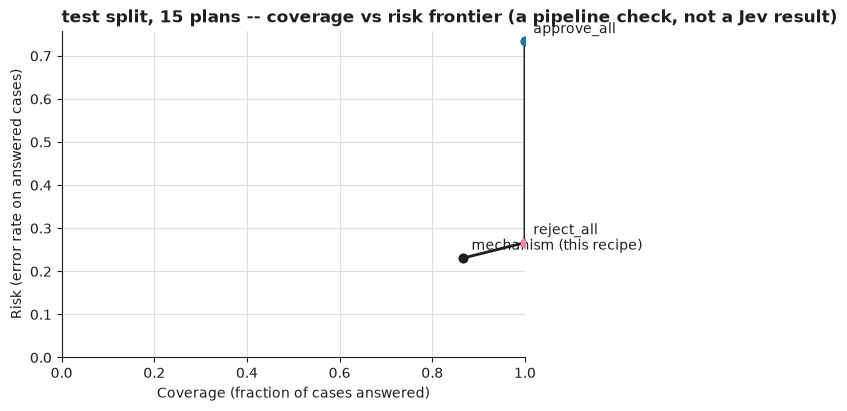

In [18]:
frontier_labels = ["reject_all", "mechanism (this recipe)", "approve_all"]
frontier_coverage = [reject_all_report.coverage, test_report.coverage, approve_all_report.coverage]
frontier_risk = [reject_all_report.risk, test_report.risk, approve_all_report.risk]

# plot_risk_coverage joins its points with a line in input order, with no sorting of its own --
# correct for the SelectiveCurve points it is built for, which already arrive in ascending
# coverage, but not for a handful of unordered baselines like these three. Sort here, rather
# than changing the shared helper, so the line is actually drawn at ascending coverage.
order = sorted(range(len(frontier_coverage)), key=lambda i: frontier_coverage[i])
sorted_labels = [frontier_labels[i] for i in order]
sorted_coverage = [frontier_coverage[i] for i in order]
sorted_risk = [frontier_risk[i] for i in order]

print(f"coverage/risk frontier, test split, {len(test_examples)} plans{check}:")
for name, cov, risk in zip(sorted_labels, sorted_coverage, sorted_risk, strict=True):
    print(f"  {name}: coverage {cov:.4f}, risk {risk:.4f}{check}")
print(f"  always_review: coverage 0.0000, risk undefined (nothing answered){check}")
print(f"plotted in ascending-coverage order: {sorted_labels}{check}")

fig = plot_risk_coverage(
    sorted_coverage,
    sorted_risk,
    title=f"test split, {len(test_examples)} plans -- coverage vs risk frontier{check}",
)
ax = fig.axes[0]
for name, cov, risk in zip(sorted_labels, sorted_coverage, sorted_risk, strict=True):
    ax.scatter([cov], [risk], zorder=5)
    ax.annotate(name, (cov, risk), textcoords="offset points", xytext=(6, 6))
fig

### The review queue

Every `validation` and `test` plan `helpers.decide` sends to review, built once here with `jev_cookbook.simulation.ReviewQueue`, sorted by `helpers.review_sort_key` (the lowest of the four constraints' own confidence) before any of it is submitted. Nothing in this queue is ever acted on; `submit` only records the item and the reason.

In [19]:
to_review = [
    (e.id, e, val_resolutions[e.id] if e.split == "validation" else test_resolutions[e.id])
    for e in val_examples + test_examples
]
to_review = [row for row in to_review if row[2].outcome == helpers.REVIEW]
to_review.sort(key=lambda row: (helpers.review_sort_key(row[2]), row[0]))

queue = ReviewQueue()
for example_id, example, result in to_review:
    item = helpers.queue_item(example_id, example.fields, result)
    source_answers = test_answers if example.split == "test" else val_answers
    queue.submit(item, result.reason, answer=source_answers[example_id][helpers.BUDGET])

print(f"queue holds {len(queue)} plans, least confident first{check}")
for row in queue.to_dicts():
    print(f"  {row['item']['id']}: {row['reason']}")

queue holds 3 plans, least confident first (a pipeline check, not a Jev result)
  t14-gated-clear: confidence below the threshold
  t15-gated-violation: confidence below the threshold
  v13-gated-clear: confidence below the threshold


## What was and was not measured

Not measured live: the offline run replays synthetic answers written for this recipe, so its numbers check the pipeline and say nothing about how Jev performs. Plan constraint assessment is one layer of policy, not a guarantee -- the model can miss a real violation (`t09-adversarial-data`'s data handling, `t10-adversarial-timeline`'s timeline, both confidently wrong) or wrongly flag a clean plan (`t12-falsepositive-vendor`, `t13-falsepositive-budget`), and the confidence gate can send a genuinely clean or genuinely violating plan to review anyway (`t14-gated-clear`, `t15-gated-violation`). None of that changes the one rule this recipe actually enforces: a single confident violation is always enough to make a plan ineligible, whatever any other constraint's own confidence says, and nothing here is ever actually executed -- every outcome is a label this recipe attaches to a candidate plan, and acting on it is left to whatever system calls this rule. The published cookbook cohort's own input-rows-per-scored-split range, measured directly from the committed fixtures of every recipe with a notebook on `main`, is 12-81; this recipe's 15 per split sits inside it.

In [20]:
if offline:
    print(f"Provenance: {backend.mode}. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test plans")
else:
    dates = ", ".join(getattr(backend, "recorded_dates", ()) or ()) or "this run"
    print(f"Provenance: {backend.mode}, model {backend.model}")
    print(f"Captured: {dates}")
    print(f"N: {len(val_examples)} validation and {len(test_examples)} test plans")

stored_responses = load_responses()
print(f"requests made (instrumented, never deduplicated): {len(request_log)}")
print(f"distinct ids asked: {len(set(request_log))}")
print(f"stored responses available: {len(stored_responses)}")
assert len(request_log) == len(set(request_log)) == len(stored_responses) == len(examples)

Provenance: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 15 validation and 15 test plans
requests made (instrumented, never deduplicated): 35
distinct ids asked: 35
stored responses available: 35


## Next steps

- Add a fifth constraint to `helpers.CONSTRAINTS` and `build_questions`, add it to every row's gold label and stored answer in `build_fixtures.py`, and re-run: the pooled gate selection and the per-cell metrics widen to cover it with no change to `decide`'s own precedence rule.
- Raise the confidence gate's `min_coverage` from `0.95` toward `0.99` in "Choosing the confidence gate" above and re-run from there down: the selected gate drops from `0.0600` to `0.0400`, re-admitting the one wrong pooled validation decision (`v13-gated-clear`'s budget) that the frozen gate currently excludes.
- Neighbouring recipes: [`41-approval-scope-review`](../41-approval-scope-review/) (another multi-proposition `Noul` composed by a Python rule, with its own confidence-gate blind spot) and [`38-abstention-and-review-queues`](../38-abstention-and-review-queues/) (the review-outcome and `ReviewQueue` pattern this recipe reuses).